# Exercise SYOTOOL's redshift evolution and extinction properties

We will test SYOTOOL's handling of redshift and extinction using a QSO template.

Imports:

In [1]:
import numpy as np
from syotools.models import Source #Camera, Telescope
from syotools.spectra import SpectralLibrary
import synphot as syn
import stsynphot as stsyn

import astropy.units as u

import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline

## Define the source template

In [2]:
# Create the source
sed = Source()

# Configure the source
# Let's start with redshift of 0 and no extinction
# We'll set the spectrum to have an AB magnitude
# of 18 in the SDSS g filter
template = 'QSO'
mag = 18
bandpass = 'sdss,g'
redshift = 0
extinction = 0
sed.set_sed(template, mag, redshift, extinction, bandpass=bandpass)

## Plot the QSO Template for $z=0$, no extinction

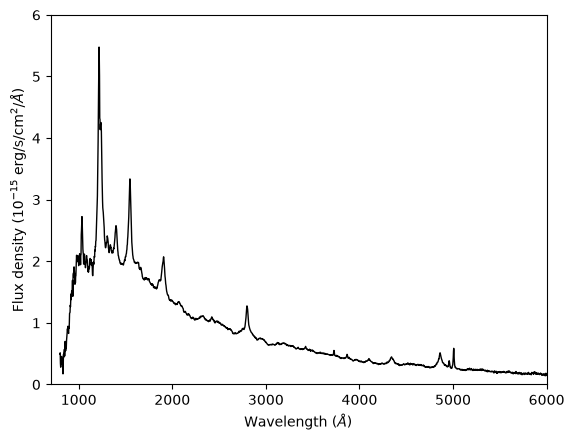

In [3]:
# Define flux array
qso_flux_rest = syn.units.convert_flux(sed.sed.waveset, sed.sed(sed.sed.waveset), syn.units.FLAM)
# Define wavelength array
qso_wave_rest = sed.sed.waveset
# Plot SED
plt.plot(qso_wave_rest.to_value(u.AA), qso_flux_rest.value*1e15, color='black',lw=1)

# Label axes
plt.xlabel(r'Wavelength ($\AA$)')
plt.ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)')

# Limit ranges on axes
plt.xlim(700,6000)
plt.ylim(0,6)

plt.show()

## Redshift the source: Trying to figure out how normalization works
### Normalize the redshifted spectrum
Compare the redshifted spectrum derived through SYOTOOLs with manually redshifting the SED. Do they agree?

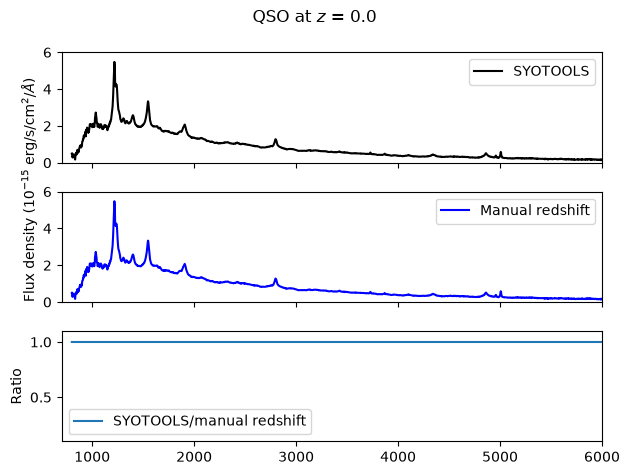

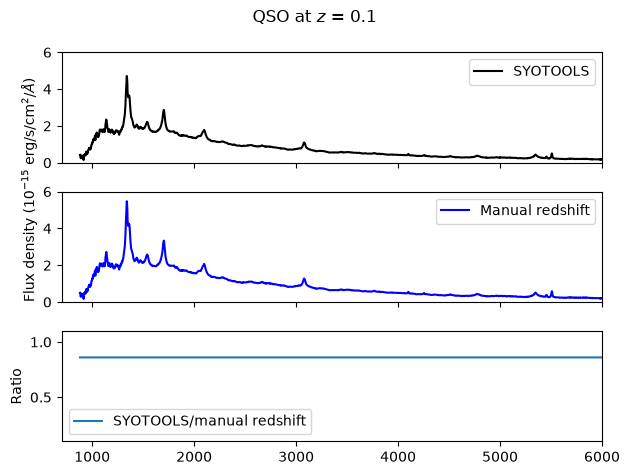

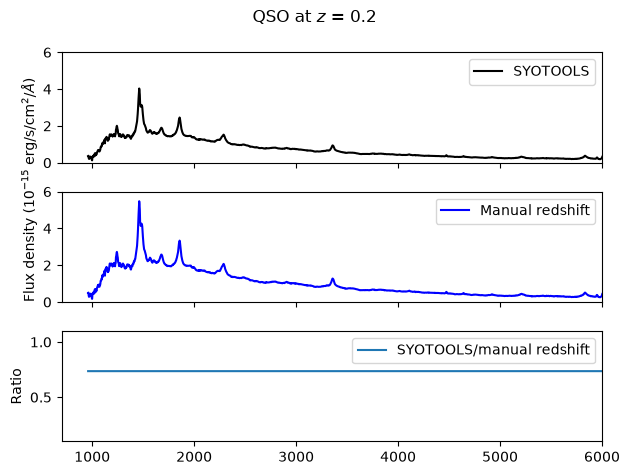

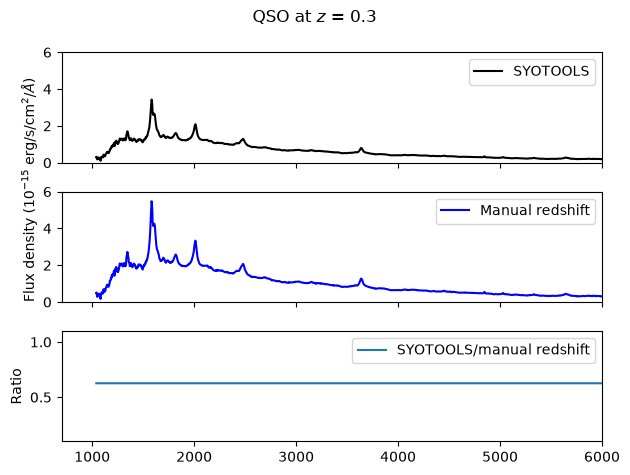

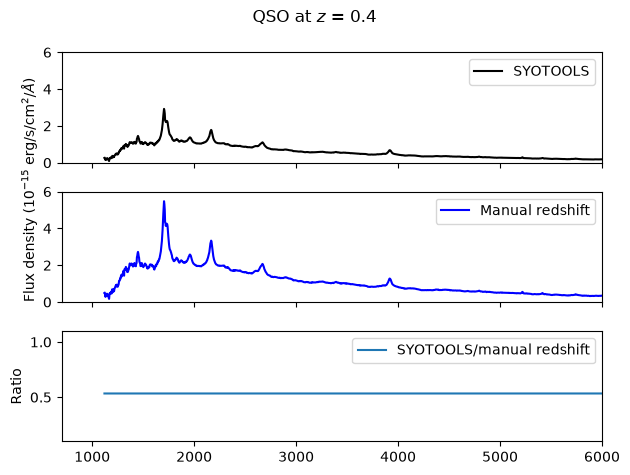

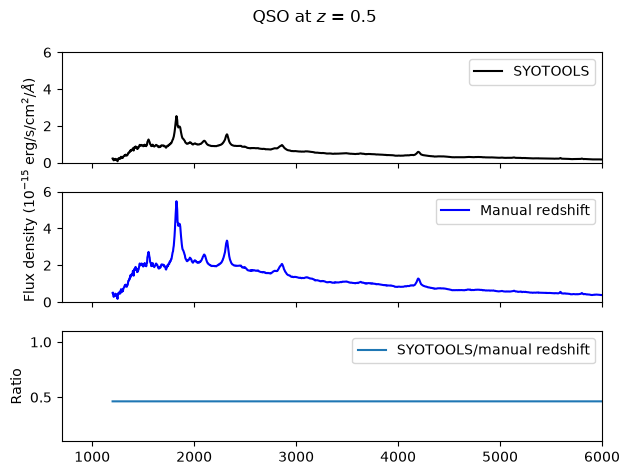

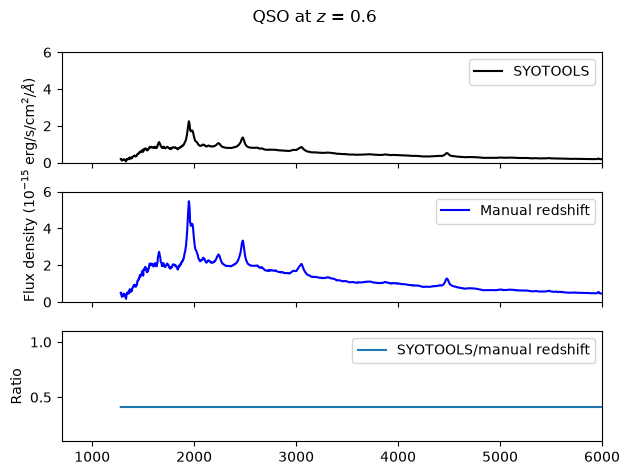

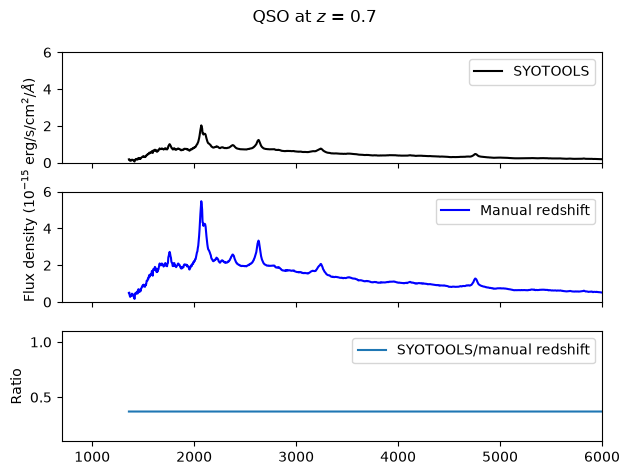

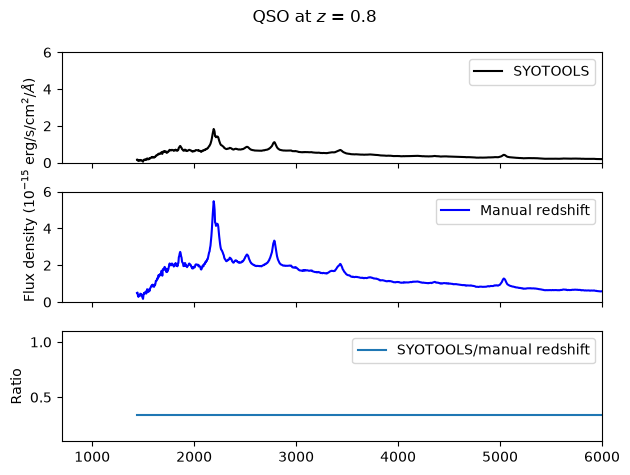

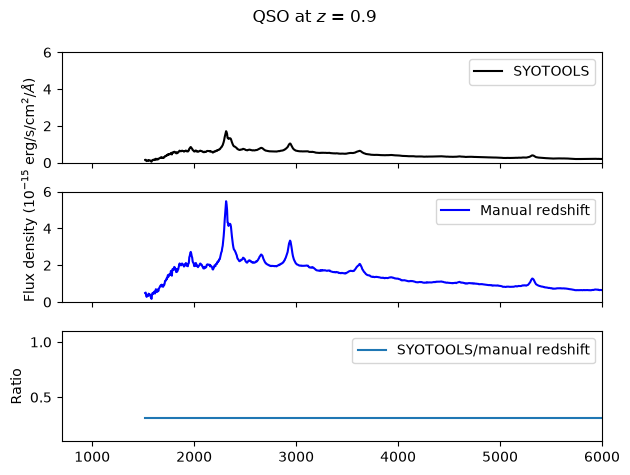

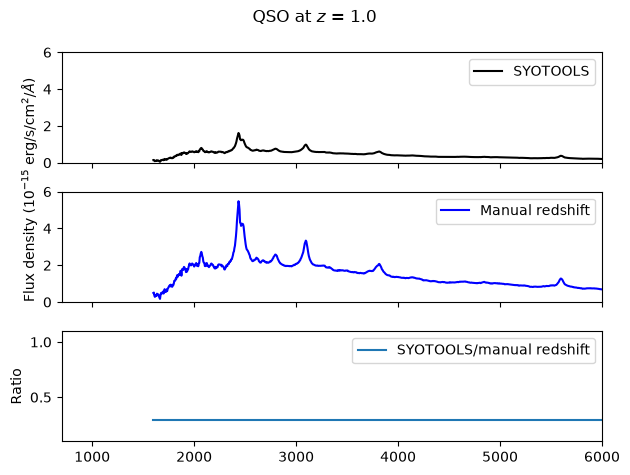

In [13]:
# Set up redshift array
z = np.arange(0,1.1,0.1)

# Cycle through the redshift array
for i in range(len(z)):

    fig, axs = plt.subplots(3,sharex=True)
    fig.suptitle(r'QSO at $z$ = '+str(np.round(z[i],1))) 

    # Define source in SYOTOOLS
    sed.set_sed(template, mag, z[i], extinction, bandpass=bandpass)
    # Define flux array
    qso_flux_z = syn.units.convert_flux(sed.sed.waveset, sed.sed(sed.sed.waveset), syn.units.FLAM)
    axs[0].plot(sed.sed.waveset.to_value(u.AA), qso_flux_z.value*1e15, color='black',
                label='SYOTOOLS')
    axs[0].set_ylim(0,6)
    axs[0].legend()
    
    
    # Manually redshift source, starting with the QSO SED defined at z = 0
    # Redshift wavelength axis:
    wave_z = qso_wave_rest*(1+z[i])
    # For flux array, normalize to the specified magnitude at the specified bandpass
    bp = stsyn.spectrum.band(bandpass) # Get the bandpass
    # Create a spectrum class for this model
    sp = syn.SourceSpectrum(syn.models.Empirical1D, points=wave_z, lookup_table=qso_flux_rest)
    # Normalize the spectrum to specified magnitude
    qso_flux_norm_z = sp.normalize(mag * u.ABmag,bp)
    # Convert to flux density units
    qso_flux_norm_z = syn.units.convert_flux(sp.waveset, sp(sp.waveset), syn.units.FLAM)
    axs[1].plot(sp.waveset, qso_flux_norm_z.value*1e15, color='blue',
                label='Manual redshift')
    axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
    axs[1].set_ylim(0,6)
    axs[1].legend()

    # Take the ratio of the two SEDs
    axs[2].plot(wave_z,qso_flux_z.value/qso_flux_norm_z.value,
                label='SYOTOOLS/manual redshift')
    axs[2].set_ylim(0.1,1.1)
    axs[2].set_ylabel('Ratio')
    axs[2].legend()
    axs[2].set_xlim(700,6000)
    

    plt.tight_layout()

## Redshift the source: Trying to figure out how normalization works
### Redshift the spectrum that was normalized at $z=0$. Don't conserve flux (just shift the wavelength axis)
Compare the redshifted spectrum derived through SYOTOOLs with manually redshifting the SED. Do they agree?

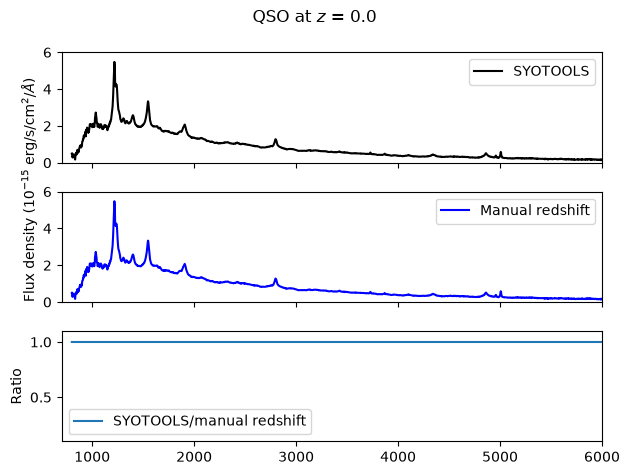

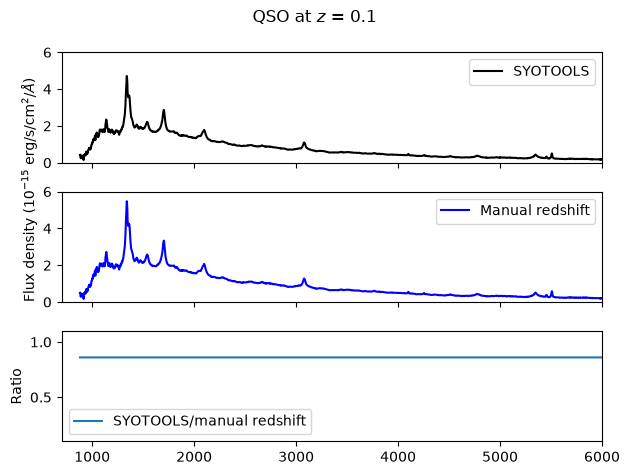

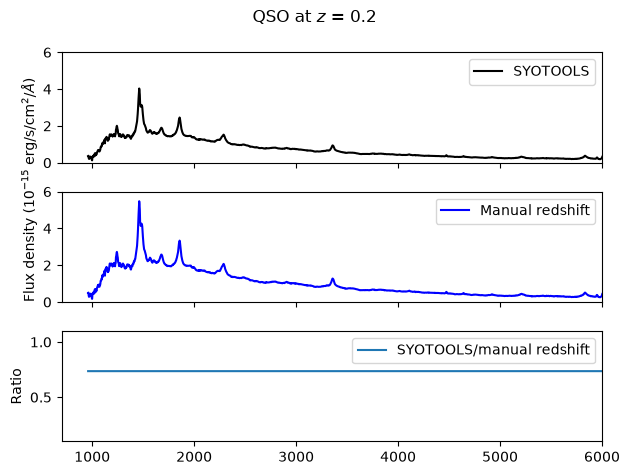

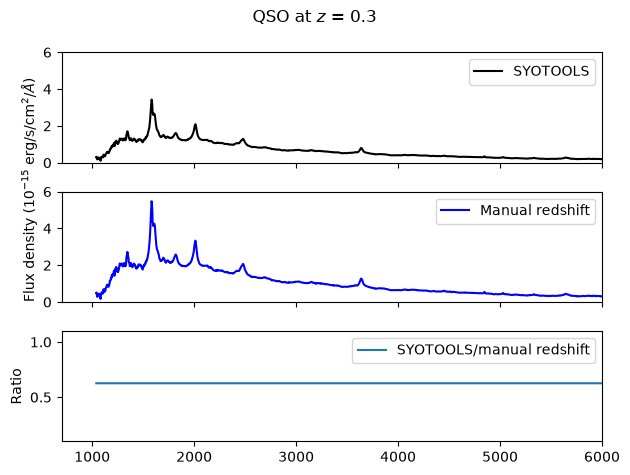

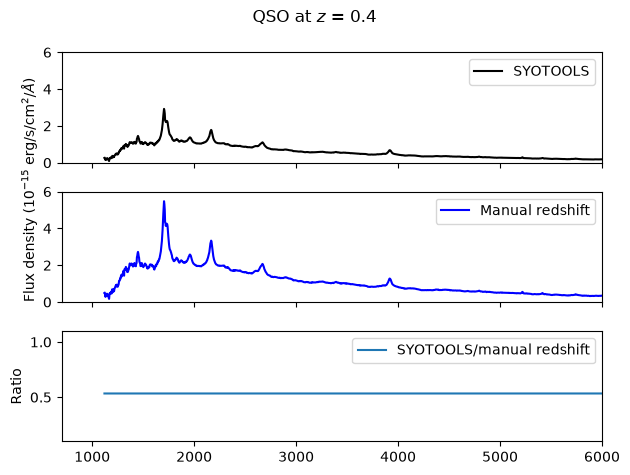

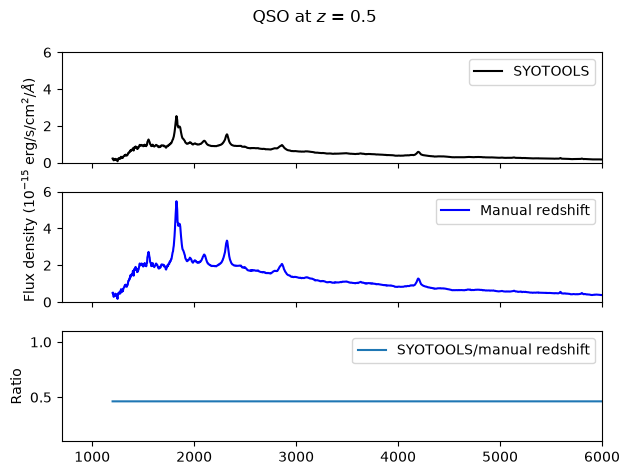

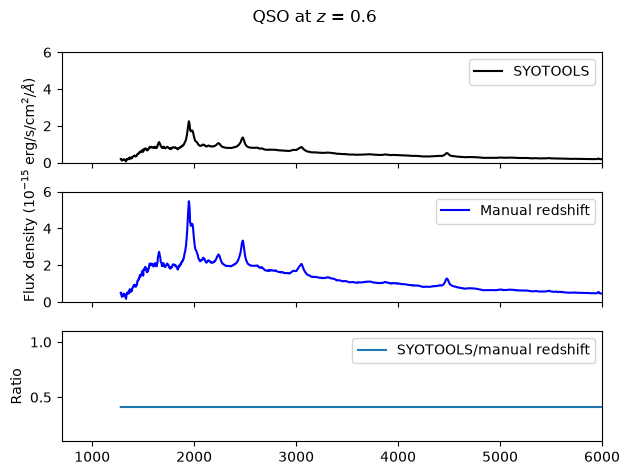

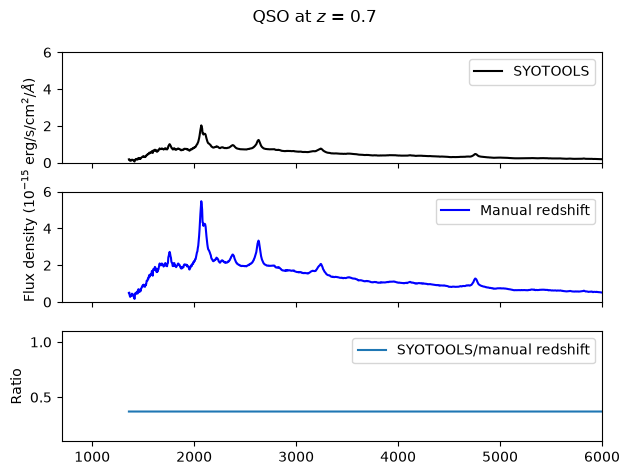

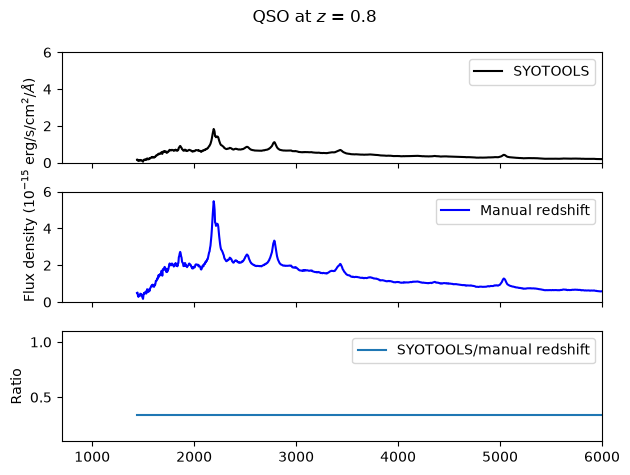

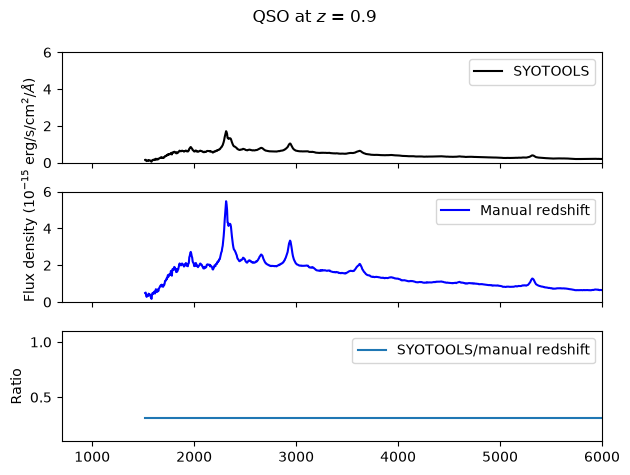

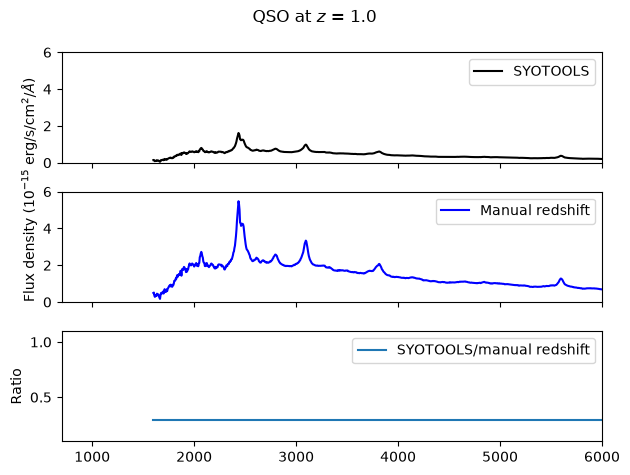

In [12]:
# Cycle through the redshift array
for i in range(len(z)):

    fig, axs = plt.subplots(3,sharex=True)
    fig.suptitle(r'QSO at $z$ = '+str(np.round(z[i],1))) 

    # Define source in SYOTOOLS
    sed.set_sed(template, mag, z[i], extinction, bandpass=bandpass)
    # Define flux array
    qso_flux_z = syn.units.convert_flux(sed.sed.waveset, sed.sed(sed.sed.waveset), syn.units.FLAM)
    axs[0].plot(sed.sed.waveset.to_value(u.AA), qso_flux_z.value*1e15, color='black',
                label='SYOTOOLS')
    axs[0].set_ylim(0,6)
    axs[0].legend()
    
    
    # Manually redshift source, starting with the QSO SED defined at z = 0
    # Redshift wavelength axis:
    wave_z = qso_wave_rest*(1+z[i])
    axs[1].plot(wave_z, qso_flux_rest*1e15, color='blue',
                label='Manual redshift')
    axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
    axs[1].set_ylim(0,6)
    axs[1].legend()

    # Take the ratio of the two SEDs
    axs[2].plot(wave_z,qso_flux_z.value/qso_flux_rest,
                label='SYOTOOLS/manual redshift')
    axs[2].set_ylim(0.1,1.1)
    axs[2].set_ylabel('Ratio')
    axs[2].legend()
    axs[2].set_xlim(700,6000)
    

    plt.tight_layout()


## Redshift the source: Trying to figure out how normalization works
### Redshift the spectrum that was normalized at $z=0$. Conserve flux 
Compare the redshifted spectrum derived through SYOTOOLs with manually redshifting the SED. Do they agree?

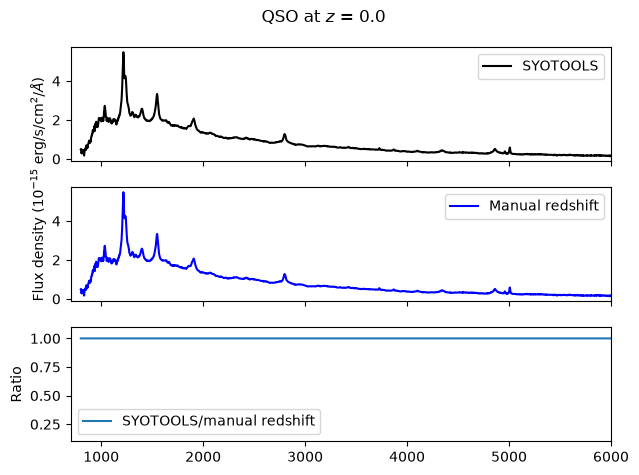

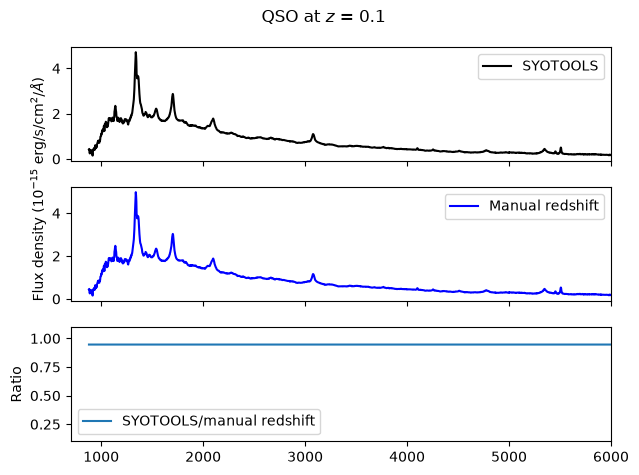

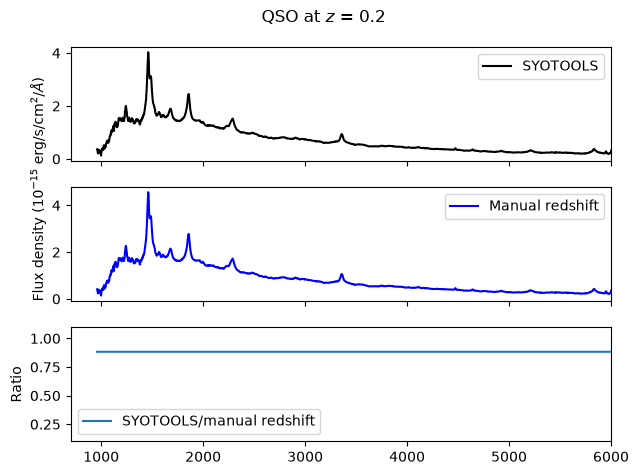

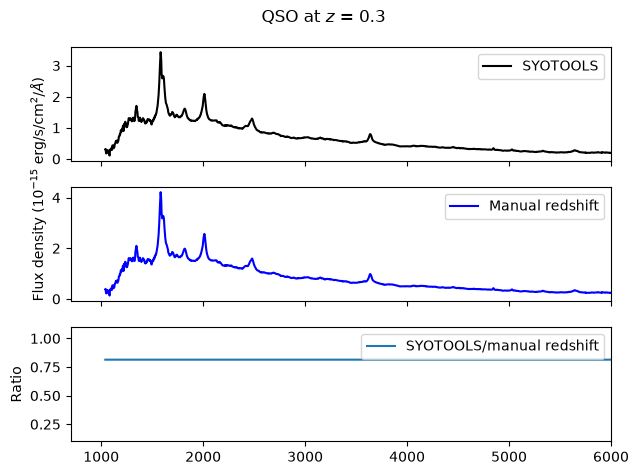

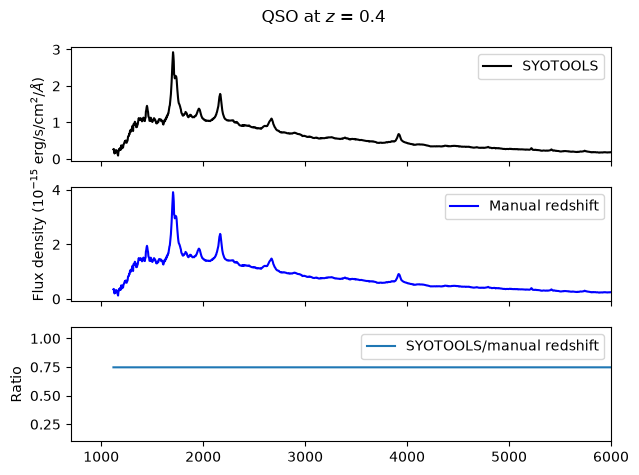

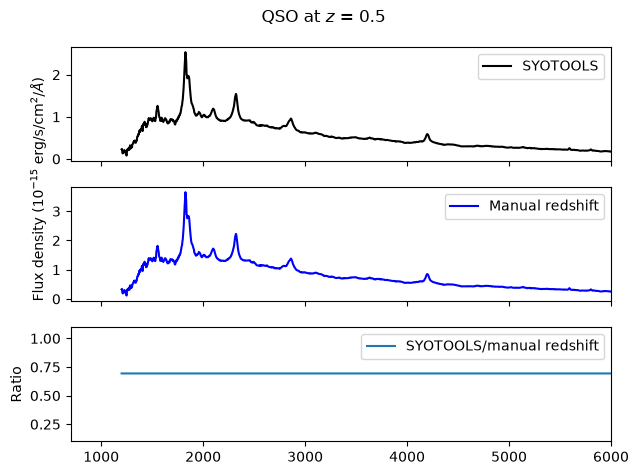

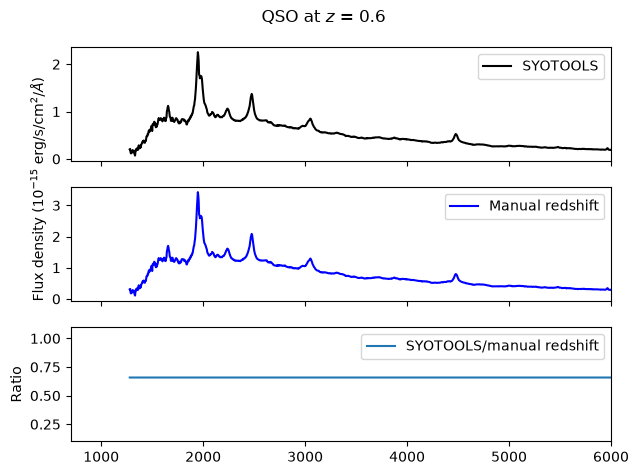

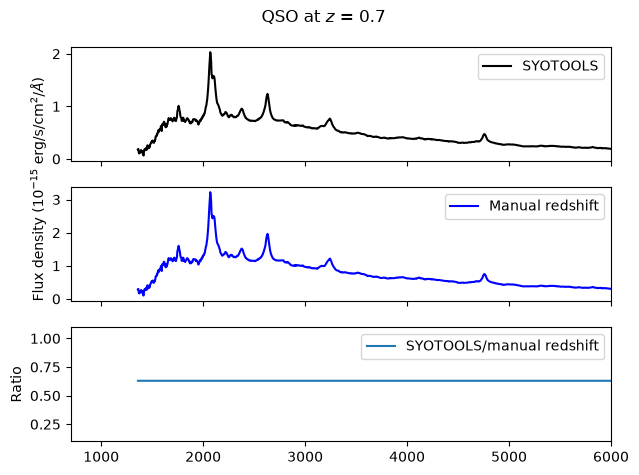

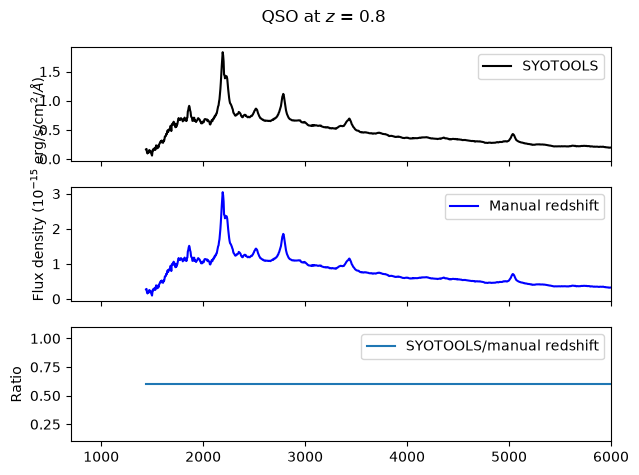

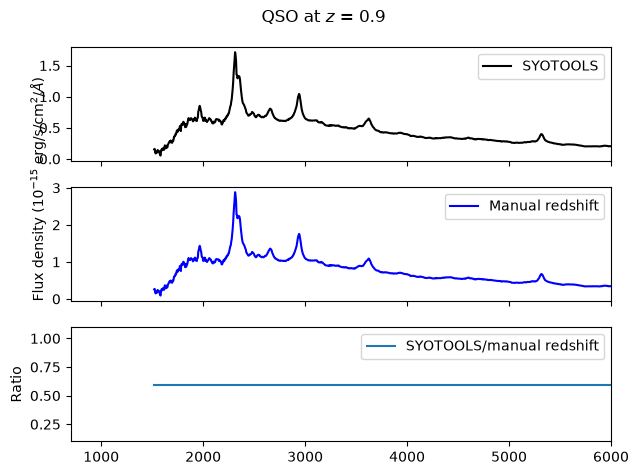

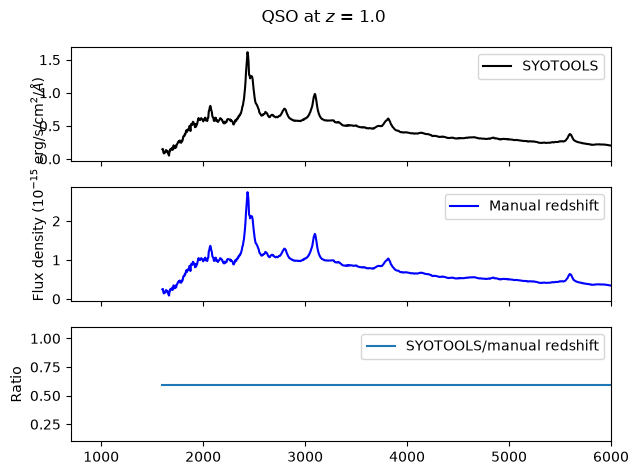

In [6]:
# Cycle through the redshift array
for i in range(len(z)):

    fig, axs = plt.subplots(3,sharex=True)
    fig.suptitle(r'QSO at $z$ = '+str(np.round(z[i],1))) 

    # Define source in SYOTOOLS
    sed.set_sed(template, mag, z[i], extinction, bandpass=bandpass)
    # Define flux array
    qso_flux_z = syn.units.convert_flux(sed.sed.waveset, sed.sed(sed.sed.waveset), syn.units.FLAM)
    axs[0].plot(sed.sed.waveset.to_value(u.AA), qso_flux_z.value*1e15, color='black',
                label='SYOTOOLS')
    axs[0].set_ylim(0,6)
    axs[0].legend()
    
    
    # Manually redshift source, starting with the QSO SED defined at z = 0
    # Redshift wavelength axis:
    wave_z = qso_wave_rest*(1+z[i])
    # Conserve flux by dividing by (1+z[i])
    flux_z_cons = qso_flux_rest/(1+z[i])
    axs[1].plot(wave_z, flux_z_cons*1e15, color='blue',
                label='Manual redshift')
    axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
    axs[0].set_ylim(0,6)
    axs[1].legend()

    # Take the ratio of the two SEDs
    axs[2].plot(wave_z,qso_flux_z.value/flux_z_cons,
                label='SYOTOOLS/manual redshift')
    axs[2].set_ylim(0.1,1.1)
    axs[2].set_ylabel('Ratio')
    axs[2].legend()
    axs[2].set_xlim(700,6000)
    

    plt.tight_layout()


Scratch space if we want to add S/N calculations

In [ ]:
# Set up the telescope architecture and select the instrument
#tel = Telescope()
#tel.set_from_hwome('EAC5')

# Select the UV MOS instrument with NUV coverage
#uv_mos = tel.instruments['UV_MOS.NUV_MOS_MOS']

# Add the source to the exposure
#uv_mos.source = sed

#Print the available grating modes
#available_uv_gratings = [band for band in uv_mos.bandnames]
#print("UV grating modes:") 
#for grating in available_uv_gratings:
#    print("   "+grating) 

#Print the default template & mode
#default_uv_template = SpectralLibrary[uv_mos.source.name]
#default_uv_band = uv_mos.band
#uv_mos.band = 'NUV_MOS.G700L'
#print("Current SED template: {}".format(default_uv_template)) 
#print("Current grating mode: {}".format(uv_mos.band)) 